# Chiaroscuro albedo baseline

This notebook builds a simple baseline for the [Chiaroscuro](https://speedyweather.github.io/Chiaroscuro.jl/dev/) albedo challenge:

1. **Data**: load MODIS satellite albedo and ERA5 inputs.
2. **Model**: train a small neural network to predict land albedo from the inputs.
3. **Analysis**: check how well it does on held-out data.
4. **Equation**: distil the network into a short formula with symbolic regression (PySR).
5. **Submission**: write the formula into a Chiaroscuro submission file, which Chiaroscuro runs in SpeedyWeather and scores.

The result is a baseline for you to beat.

**Before you start:** use the shared Python environment as this notebook's kernel.

1. Open the command palette (Ctrl/Cmd+Shift+P) and run **Python: Select Interpreter → Enter interpreter path…**, then paste
   `/gws/ssde/j25b/era5_physical_process_dataset/climate_modelling26/env/venv/bin/python`
2. In this notebook, click **Select Kernel → Python Environments** and pick that interpreter (Python 3.12).

The environment limits every tool to 2 CPU threads, because the sci nodes are shared.

In [12]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import xarray as xr
from IPython.display import display
from torch import nn

assert "CHIARO_ENV" in os.environ, (
    "Wrong kernel: select /gws/ssde/j25b/era5_physical_process_dataset/climate_modelling26/env/venv/bin/python (see the note above)."
)

DATA = Path(os.environ["CHIARO_ENV"]).parent / "data"  # data/ sits next to env/
DERIVED = DATA / "derived"
pd.set_option("display.max_colwidth", 120)

## 1. Load the data

The data come as three tables, `train.parquet`, `val.parquet` and `test.parquet`, for each hemisphere: `data/derived/east/` (0–180˚E) and `data/derived/west/` (180–360˚E). We use the **eastern hemisphere**:

- **One row per land grid cell and month** where MODIS has a good-quality albedo. 
- **The dates are the 16th of each month of 2023, 2024 and 2025**, on a 0.25° grid. All fields are daily means.
- **The columns are the variables**, named as Chiaroscuro's `albedo(inputs)` where one matches. Values and units are as in Greg's data.
- **The target is `wsa_shortwave`**, MODIS shortwave white-sky albedo (land only).

Each table is a separate year: `train` is 2023, `val` is 2024 and `test` is 2025. All three years cover the same places, so the scores show how well the network does in a new year, not in new places. The western hemisphere is left for you: use it to test your model in new places.

In [13]:
REGION = "east"  # 0-180˚E; the western hemisphere (180-360˚E) is in data/derived/west/
train = pd.read_parquet(DERIVED / REGION / "train.parquet")
val = pd.read_parquet(DERIVED / REGION / "val.parquet")
test = pd.read_parquet(DERIVED / REGION / "test.parquet")
print(f"train: {len(train):,} rows | val: {len(val):,} rows | test: {len(test):,} rows | {train.shape[1]} columns")
print("years:", {name: sorted(df["time"].dt.year.unique().tolist()) for name, df in [("train", train), ("val", val), ("test", test)]})

# how the tables were made, stored inside the parquet file
info = json.loads(pq.read_schema(DERIVED / REGION / "train.parquet").metadata[b"chiaroscuro"])
split = info["split"]
print(f"split: {split['method']} | {REGION}: {split['regions'][REGION]}")

# train.head()

train: 1,250,303 rows | val: 1,222,944 rows | test: 1,202,316 rows | 23 columns
years: {'train': [2023], 'val': [2024], 'test': [2025]}
split: by hemisphere and year: train, val and test are separate years | east: 0 <= lond < 180


## 2. Available variables

Every column, with its role, units and description. Columns are named as Chiaroscuro's inputs where one matches; `source` is the name in Greg's files, as used in `data/README.md`.

- **input**: possible predictors, from ERA5.
- **target**: `wsa_shortwave`, the MODIS shortwave white-sky albedo (the only MODIS variable we keep).
- **coordinate**: time and position.
- **quality**: the fraction of each cell with valid data.

In [14]:
# roles from the source files (only their headers are read)
in_features = set(xr.open_dataset(DATA / "features.nc").data_vars)
in_targets = set(xr.open_dataset(DATA / "targets.nc").data_vars)


def source(name):
    """The column's name in Greg's files (the tables use Chiaroscuro's input names)."""
    return info["columns"][name].get("source_variable", name)


def role(name):
    if name in ("time", "latd", "lond"):
        return "coordinate"
    if source(name) in in_features and source(name) in in_targets:
        return "quality"
    return "target" if source(name) in in_targets else "input"


variables = pd.DataFrame(
    {
        "variable": c,
        "role": role(c),
        "source": source(c),
        "units": info["columns"][c].get("units", ""),
        "description": info["columns"][c].get("long_name", ""),
    }
    for c in train.columns
)
variables

,variable,role,source,units,description
0,time,coordinate,time,,
1,latd,coordinate,latitude,degrees_north,
2,lond,coordinate,longitude,degrees_east,
3,high_vegetation_cover,input,cvh,fraction,"High vegetation cover fraction (ERA5-Land, static)"
4,low_vegetation_cover,input,cvl,fraction,"Low vegetation cover fraction (ERA5-Land, static)"
5,soil_moisture_1,input,swvl1,m³/m³,"Volumetric soil water, layer 1 (0-7 cm), daily mean (ERA5-Land)"
6,soil_temperature_1,input,stl1,K,"Soil temperature, layer 1 (0-7 cm), daily mean (ERA5-Land)"
7,soil_moisture_2,input,swvl4,m³/m³,"Volumetric soil water, layer 4 (100-289 cm), daily mean (ERA5-Land)"
8,soil_temperature_2,input,stl4,K,"Soil temperature, layer 4 (100-289 cm), daily mean (ERA5-Land)"
9,orography,input,z,m,"Surface height (orography) (ERA5-Land, static)"


## 3. Select the inputs


We start with eight inputs. The tables already use Chiaroscuro's names, so the equation we find later can go straight into `albedo(inputs)`.

| Input | Greg's name | Units |
|---|---|---|
| `cos_latd` | cosine of `latitude` | 1 |
| `sin_lond`, `cos_lond` | sine and cosine of `longitude` | 1 |
| `orography` | `z` | m |
| `high_vegetation_cover` | `cvh` | 1 |
| `low_vegetation_cover` | `cvl` | 1 |
| `high_vegetation_leaf_area` | `lai_hv` | m²/m² |
| `low_vegetation_leaf_area` | `lai_lv` | m²/m² |

**Latitude and longitude as cosines and sines.** The cosine of latitude is 1 at the equator and 0 at both poles, so one input can say "towards the poles" in either hemisphere, which raw latitude can't. Longitude wraps around (0˚E = 360˚E), so we use its sine and cosine rather than the angle: places either side of 0˚E then get almost the same inputs. Chiaroscuro gives only `latd` and `lond`, so a submission computes these itself with `cosd(latd)`, `sind(lond)` and `cosd(lond)` (sine and cosine in degrees). We train on 0–180˚E only, where `sin_lond` is between 0 and 1. In the western hemisphere it is negative, which the network never sees in training.

The target is `wsa_shortwave`, the MODIS shortwave white-sky albedo.

In [15]:
# column names in the tables (Chiaroscuro's input names, already in its units), plus cos_latd, sin_lond, cos_lond
INPUTS = [
    "cos_latd",                   # [1] cosine of latd, computed in select_inputs
    "sin_lond",                   # [1] sine of lond, computed in select_inputs
    "cos_lond",                   # [1] cosine of lond, computed in select_inputs
    "orography",                  # [m]
    "high_vegetation_cover",      # [1]
    "low_vegetation_cover",       # [1]
    "high_vegetation_leaf_area",  # [m²/m²]
    "low_vegetation_leaf_area",   # [m²/m²]
]
TARGET = "wsa_shortwave"  # MODIS shortwave white-sky albedo [1]


def select_inputs(df):
    lond = np.deg2rad(df["lond"])  # longitude wraps around (0˚E = 360˚E), so use its sine and cosine
    computed = {"cos_latd": np.cos(np.deg2rad(df["latd"])), "sin_lond": np.sin(lond), "cos_lond": np.cos(lond)}
    return pd.DataFrame({name: computed[name] if name in computed else df[name] for name in INPUTS})


X_train, y_train = select_inputs(train), train[TARGET]
X_val, y_val = select_inputs(val), val[TARGET]
print(f"inputs: {X_train.shape[1]} | train: {len(X_train):,} rows | val: {len(X_val):,} rows | target: {TARGET}")

pd.concat([X_train, y_train], axis=1).describe().T[["mean", "std", "min", "max"]]

inputs: 8 | train: 1,250,303 rows | val: 1,222,944 rows | target: wsa_shortwave


,mean,std,min,max
cos_latd,0.728804,0.241348,6.123234e-17,1.000000
sin_lond,0.667078,0.274441,0.000000e+00,1.000000
cos_lond,0.251719,0.645234,-9.999905e-01,1.000000
orography,856.716614,1025.022949,-1.742696e+02,5700.917480
high_vegetation_cover,0.237422,0.356972,0.000000e+00,1.000000
low_vegetation_cover,0.498893,0.420573,0.000000e+00,1.000000
high_vegetation_leaf_area,1.212265,1.463815,0.000000e+00,6.717854
low_vegetation_leaf_area,1.029947,0.874367,0.000000e+00,5.034035
wsa_shortwave,0.250111,0.198258,1.683324e-03,0.884994


## 4. Standardise the inputs

Neural networks train best when all inputs have a similar scale. So we shift and scale each input to mean 0 and standard deviation 1.

The mean and standard deviation come from the training set only, so nothing about `val` leaks into training. The target stays in albedo units (0–1).

We keep the unscaled `X_train` and `X_val` too. Symbolic regression will use those, so its equation comes out in physical units.

In [16]:
# statistics from the training set only
mean, std = X_train.mean(), X_train.std()


def standardise(X):
    return (X - mean) / std


X_train_std, X_val_std = standardise(X_train), standardise(X_val)

# check: train should be exactly mean 0 / std 1, val close to it
pd.DataFrame({
    "mean": mean,
    "std": std,
    "train mean after": X_train_std.mean(),
    "train std after": X_train_std.std(),
    "val mean after": X_val_std.mean(),
    "val std after": X_val_std.std(),
}).round(3)

,mean,std,train mean after,train std after,val mean after,val std after
cos_latd,0.729,0.241,0.0,1.0,-0.008,1.003
sin_lond,0.667,0.274,-0.0,1.0,-0.018,0.998
cos_lond,0.252,0.645,-0.0,1.0,0.018,1.001
orography,856.717,1025.023,-0.0,1.0,0.018,1.011
high_vegetation_cover,0.237,0.357,0.0,1.0,-0.006,0.996
low_vegetation_cover,0.499,0.421,0.0,1.0,-0.010,1.001
high_vegetation_leaf_area,1.212,1.464,-0.0,1.0,-0.009,0.998
low_vegetation_leaf_area,1.030,0.874,0.0,1.0,-0.009,0.998


## 5. Train a small neural network

A small multilayer perceptron (MLP): 8 inputs → 16 → 1, with ReLU activations. A sigmoid on the output keeps predictions between 0 and 1.

- **Loss:** mean squared error, weighted by grid-cell area (cos latitude). On a regular latitude–longitude grid, cells get smaller towards the poles. Weighting makes every square kilometre count equally.
- **Training:** Adam with learning rate 0.001, batches of 4,096 rows, and 30 epochs, which is about where the validation error levels off. We keep the final weights.
- **Seeds:** we train 3 networks with different random seeds, to see how much the result depends on chance.

We report the area-weighted RMSE (root mean squared error), in albedo units.

In [17]:
def area_weights(df):
    """cos(latitude) per row, scaled to mean 1."""
    w = np.cos(np.deg2rad(df["latd"].to_numpy()))
    return w / w.mean()


def to_tensor(a):
    return torch.as_tensor(np.array(a, dtype=np.float32))  # a copy: pandas arrays from parquet can be read-only


# inputs, targets (as columns) and area weights as float32 tensors
Xt, yt, wt = to_tensor(X_train_std), to_tensor(y_train)[:, None], to_tensor(area_weights(train))[:, None]
Xv, yv, wv = to_tensor(X_val_std), to_tensor(y_val)[:, None], to_tensor(area_weights(val))[:, None]


def make_mlp(n_inputs, width=16):
    return nn.Sequential(
        nn.Linear(n_inputs, width), nn.ReLU(),
        nn.Linear(width, 1), nn.Sigmoid(),
    )


@torch.no_grad()
def weighted_rmse(model, X, y, w):
    return torch.sqrt((w * (model(X) - y) ** 2).sum() / w.sum()).item()


def train_mlp(seed, epochs=30, batch_size=4096, lr=1e-3):
    torch.manual_seed(seed)  # fixes the initial weights and the batch order
    model = make_mlp(Xt.shape[1])
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        for batch in torch.randperm(len(Xt)).split(batch_size):
            loss = (wt[batch] * (model(Xt[batch]) - yt[batch]) ** 2).mean()  # area-weighted MSE
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()
        model.eval()
        scores = {"train_rmse": weighted_rmse(model, Xt, yt, wt), "val_rmse": weighted_rmse(model, Xv, yv, wv)}
        history.append({"seed": seed, "epoch": epoch, **scores})
        print(f"seed {seed}, epoch {epoch:2d}: train RMSE {scores['train_rmse']:.4f}, val RMSE {scores['val_rmse']:.4f}")
    return model, history


print(f"{sum(p.numel() for p in make_mlp(Xt.shape[1]).parameters()):,} parameters, torch threads: {torch.get_num_threads()}")

161 parameters, torch threads: 2


In [18]:
SEEDS = [0, 1, 2]
models, histories = {}, []
for seed in SEEDS:
    models[seed], history = train_mlp(seed)
    histories += history
history = pd.DataFrame(histories)

# summary: final epoch, mean ± standard deviation over seeds
final = history[history["epoch"] == history["epoch"].max()]
w_train, w_val = area_weights(train), area_weights(val)
constant = np.average(y_train, weights=w_train)  # predict the (area-weighted) mean albedo everywhere
constant_rmse = np.sqrt(np.average((y_val - constant) ** 2, weights=w_val))
print(f"\nval RMSE, area-weighted: MLP {final['val_rmse'].mean():.4f} ± {final['val_rmse'].std():.4f} "
      f"({len(SEEDS)} seeds) | constant {constant:.3f}: {constant_rmse:.4f}")

seed 0, epoch  1: train RMSE 0.0863, val RMSE 0.0861
seed 0, epoch  2: train RMSE 0.0770, val RMSE 0.0764
seed 0, epoch  3: train RMSE 0.0735, val RMSE 0.0730
seed 0, epoch  4: train RMSE 0.0704, val RMSE 0.0701
seed 0, epoch  5: train RMSE 0.0690, val RMSE 0.0688
seed 0, epoch  6: train RMSE 0.0680, val RMSE 0.0678
seed 0, epoch  7: train RMSE 0.0673, val RMSE 0.0671
seed 0, epoch  8: train RMSE 0.0666, val RMSE 0.0665
seed 0, epoch  9: train RMSE 0.0660, val RMSE 0.0659
seed 0, epoch 10: train RMSE 0.0654, val RMSE 0.0653
seed 0, epoch 11: train RMSE 0.0648, val RMSE 0.0647
seed 0, epoch 12: train RMSE 0.0643, val RMSE 0.0642
seed 0, epoch 13: train RMSE 0.0638, val RMSE 0.0637
seed 0, epoch 14: train RMSE 0.0632, val RMSE 0.0632
seed 0, epoch 15: train RMSE 0.0627, val RMSE 0.0626
seed 0, epoch 16: train RMSE 0.0623, val RMSE 0.0621
seed 0, epoch 17: train RMSE 0.0619, val RMSE 0.0617
seed 0, epoch 18: train RMSE 0.0615, val RMSE 0.0614
seed 0, epoch 19: train RMSE 0.0612, val RMSE 

## 6. Training curves and test performance


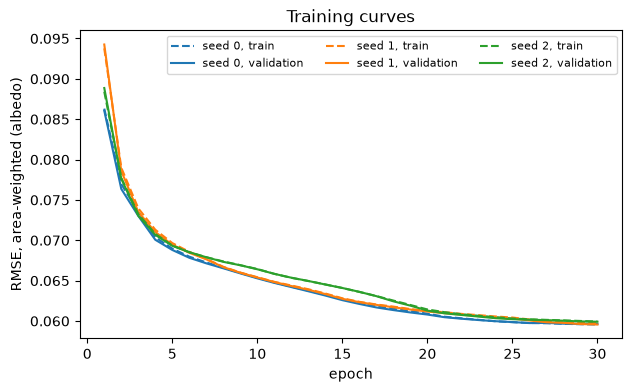

In [19]:
# training curves: area-weighted RMSE after each epoch, one colour per seed
fig, ax = plt.subplots(figsize=(7, 4))
for i, (seed, h) in enumerate(history.groupby("seed")):
    ax.plot(h["epoch"], h["train_rmse"], "--", color=f"C{i}", label=f"seed {seed}, train")
    ax.plot(h["epoch"], h["val_rmse"], "-", color=f"C{i}", label=f"seed {seed}, validation")
ax.set_xlabel("epoch")
ax.set_ylabel("RMSE, area-weighted (albedo)")
ax.set_title("Training curves")
ax.legend(ncol=len(SEEDS), fontsize=8)
plt.show()

,RMSE (area-weighted),RMSE (unweighted),bias (area-weighted),R² (area-weighted)
MLP seed 0,0.0559,0.0629,0.0052,0.8167
MLP seed 1,0.0554,0.0613,0.0055,0.8202
MLP seed 2,0.0556,0.0615,0.0033,0.8188
"MLP, mean over seeds",0.0556,0.0619,0.0046,0.8185
"MLP, std over seeds",0.0003,0.0009,0.0012,0.0018
constant (0.216),0.1306,0.2010,0.0029,-0.0005


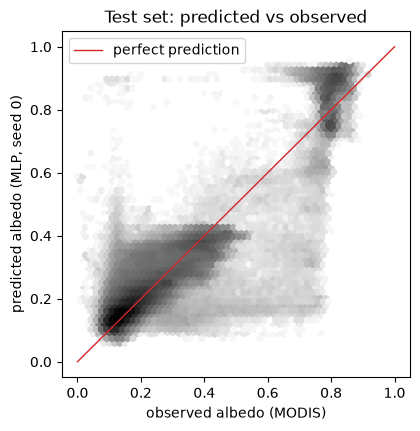

In [20]:
# test set: all of 2025 in the eastern hemisphere, loaded in section 1
X_test_std, y_test, w_test = standardise(select_inputs(test)), test[TARGET].to_numpy(), area_weights(test)


def scores(pred, y, w):
    """RMSE, bias and R² of predictions `pred` against targets `y`, with area weights `w`."""
    err = pred - y
    mse = np.average(err**2, weights=w)
    var = np.average((y - np.average(y, weights=w)) ** 2, weights=w)
    return {
        "RMSE (area-weighted)": np.sqrt(mse),
        "RMSE (unweighted)": np.sqrt(np.mean(err**2)),
        "bias (area-weighted)": np.average(err, weights=w),
        "R² (area-weighted)": 1 - mse / var,
    }


with torch.no_grad():
    predictions = {seed: model(to_tensor(X_test_std)).numpy().ravel() for seed, model in models.items()}

table = pd.DataFrame({f"MLP seed {seed}": scores(pred, y_test, w_test) for seed, pred in predictions.items()}).T
per_seed = table.copy()
table.loc["MLP, mean over seeds"] = per_seed.mean()
table.loc["MLP, std over seeds"] = per_seed.std()
table.loc[f"constant ({constant:.3f})"] = scores(np.full_like(y_test, constant), y_test, w_test)
display(table.round(4))

# predicted vs observed albedo for the first seed (darker = more grid cells)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.hexbin(y_test, predictions[SEEDS[0]], gridsize=60, bins="log", cmap="Greys", extent=(0, 1, 0, 1))
ax.plot([0, 1], [0, 1], color="C3", lw=1, label="perfect prediction")
ax.set_xlabel("observed albedo (MODIS)")
ax.set_ylabel(f"predicted albedo (MLP, seed {SEEDS[0]})")
ax.set_title("Test set: predicted vs observed")
ax.legend(loc="upper left")
plt.show()

## 7. Distil the network into an equation (symbolic regression)

Symbolic regression (PySR) searches for a short formula, built from `+ − × ÷` and `exp`, that reproduces the network. A formula can be written straight into Chiaroscuro's `albedo(inputs)` while the neural network can't.

- **Inputs in their physical units.** We use the unscaled inputs (`X_train`), not the standardised ones. The formula then works directly on Chiaroscuro's inputs (plus `cos_latd`, `sin_lond` and `cos_lond`, computed as in section 3), with no standardisation to copy into Julia.
- **Target: the network's predictions, in albedo units.** We fit the network rather than the MODIS data ("distillation"), because the network gives a smooth, noise-free target. Its predictions are already albedo (0–1), because we never standardised the target, so there is nothing to undo. We use the mean of the 3 seeds' networks.
- **Sample:** 5,000 random training rows, with area weights, to keep the search to about a minute.
- **Settings:** formulas of up to 20 symbols, 100 iterations, and a fixed seed so everyone gets the same result.
- **Choosing the formula:** we take the most accurate one (`model_selection="accuracy"`). PySR's default prefers shorter formulas, and here those leave out latitude and longitude.


In [21]:
import warnings

# Importing PySR starts Julia (about 15 s). Two of its warnings don't apply here: we cap its threads on purpose
# (shared sci nodes), and the shared environment loads Julia's C++ library first, so importing torch earlier is safe.
warnings.filterwarnings("ignore", message="PYTHON_JULIACALL_THREADS")
warnings.filterwarnings("ignore", message="torch was imported before juliacall")
from pysr import PySRRegressor


@torch.no_grad()
def mlp_predict(X):
    """Mean prediction of the seeds' networks for unscaled inputs X, in albedo units."""
    X_std = to_tensor(standardise(X))
    return np.mean([model(X_std).numpy().ravel() for model in models.values()], axis=0)


rows = np.random.default_rng(0).choice(len(X_train), size=5000, replace=False)
X_sr = X_train.iloc[rows]                  # inputs in physical units, NOT standardised
y_sr = mlp_predict(X_sr)                   # the network's albedo for these inputs
w_sr = area_weights(train.iloc[rows])      # area weights, as in training

sr = PySRRegressor(
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["exp"],
    maxsize=20,
    niterations=100,
    model_selection="accuracy",  # the most accurate formula (the default prefers shorter ones)
    random_state=0,
    deterministic=True,
    parallelism="serial",     # required for deterministic results
    timeout_in_seconds=600,
    progress=False,
    verbosity=0,
    temp_equation_file=True,
)
sr.fit(X_sr, y_sr, weights=w_sr)    # variable names are taken from the column names
print("chosen equation:  albedo =", sr.get_best()["equation"])

chosen equation:  albedo = 0.9197872 / (((low_vegetation_leaf_area + exp(high_vegetation_cover + cos_latd)) - (sin_lond * (0.28641453 - ((cos_latd * sin_lond) + high_vegetation_cover)))) + low_vegetation_cover)


,RMSE (area-weighted),RMSE (unweighted),bias (area-weighted),R² (area-weighted)
SR equation,0.0701,0.0823,0.0071,0.7117
MLP (mean of seeds),0.0545,0.0608,0.0046,0.8255
constant (0.216),0.1306,0.2010,0.0029,-0.0005


equation:  albedo = 0.9197872 / (((low_vegetation_leaf_area + exp(high_vegetation_cover + cos_latd)) - (sin_lond * (0.28641453 - ((cos_latd * sin_lond) + high_vegetation_cover)))) + low_vegetation_cover)
RMSE between equation and network: 0.0414


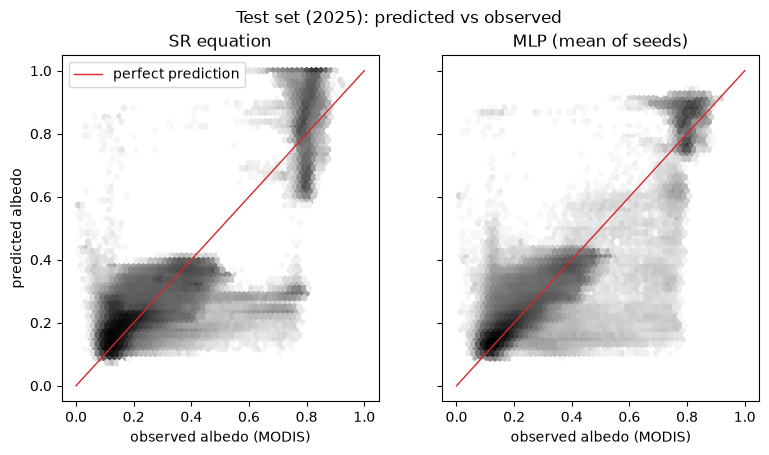

In [22]:
# compare the symbolic equation with the network on the test set (2025), using unscaled inputs
X_test = select_inputs(test)
test_predictions = {
    "SR equation": np.clip(sr.predict(X_test), 0, 1),  # clipped to 0-1, as Chiaroscuro requires
    "MLP (mean of seeds)": mlp_predict(X_test),
}
comparison = pd.DataFrame({name: scores(pred, y_test, w_test) for name, pred in test_predictions.items()}).T
comparison.loc[f"constant ({constant:.3f})"] = scores(np.full_like(y_test, constant), y_test, w_test)
display(comparison.round(4))

# how closely the equation reproduces the network it was distilled from (area-weighted)
gap = test_predictions["SR equation"] - test_predictions["MLP (mean of seeds)"]
print("equation:  albedo =", sr.get_best()["equation"])
print(f"RMSE between equation and network: {np.sqrt(np.average(gap**2, weights=w_test)):.4f}")

# predicted vs observed, side by side (darker = more grid cells)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True)
for ax, (name, pred) in zip(axes, test_predictions.items()):
    ax.hexbin(y_test, pred, gridsize=60, bins="log", cmap="Greys", extent=(0, 1, 0, 1))
    ax.plot([0, 1], [0, 1], color="C3", lw=1, label="perfect prediction")
    ax.set_title(name)
    ax.set_xlabel("observed albedo (MODIS)")
axes[0].set_ylabel("predicted albedo")
axes[0].legend(loc="upper left")
fig.suptitle("Test set (2025): predicted vs observed")
plt.show()

## 8. Create Chiaroscuro submission

To enter the Chiaroscuro challenge, put your equation into a submission file:

1. **Read** Chiaroscuro's [instructions](https://speedyweather.github.io/Chiaroscuro.jl/dev/instructions/) and [how to submit](https://speedyweather.github.io/Chiaroscuro.jl/dev/submit/).
2. **Create a Julia file** named after you, e.g. `jane_doe.jl` (`symbolic_regression.jl` is already taken).
3. **Set `name` and `description`**: your name, and under 10 words about your submission.
4. **Paste your equation** from section 7 into the `land = ...` line. Yours may differ from the example.
5. **Unpack every input your equation uses** in the `(; ...) = inputs` lines, and compute the ones we made in section 3: `cos_latd = cosd(latd)`, `sin_lond = sind(lond)` and `cos_lond = cosd(lond)` (`cosd` and `sind` take degrees).
6. **Submit:** open a pull request that adds your file to the [`submissions` folder](https://github.com/SpeedyWeather/Chiaroscuro.jl/tree/main/submissions). Chiaroscuro runs it in SpeedyWeather and scores it on the [leaderboard](https://speedyweather.github.io/Chiaroscuro.jl/dev/leaderboard/).

The example also covers what the equation can't:

- **Ocean:** the equation was fitted on land only, so the ocean gets a simple open-water and sea-ice rule from Chiaroscuro's examples, weighted by `land_fraction`.
- **Range:** `clamp` keeps the albedo between 0 and 1, as Chiaroscuro requires. The equation can go above 1 on bare land near the poles.

**Example submission file**, using the equation from section 7 above:

```julia
name = "Your Name"
description = "Symbolic regression of a neural network"

function albedo(inputs)
    (; latd, lond, land_fraction, sea_ice_concentration) = inputs
    (; high_vegetation_cover, low_vegetation_cover, low_vegetation_leaf_area) = inputs

    # land: the equation from section 7, with latitude and longitude computed as in section 3
    cos_latd = cosd(latd)
    sin_lond = sind(lond)
    land = 0.9197872 / (((low_vegetation_leaf_area + exp(high_vegetation_cover + cos_latd)) - (sin_lond * (0.28641453 - ((cos_latd * sin_lond) + high_vegetation_cover)))) + low_vegetation_cover)

    # ocean: open water and sea ice (the equation was fitted on land only)
    ocean = 0.06 * (1 - sea_ice_concentration) + 0.6 * sea_ice_concentration

    # weight by the fraction of land in the grid cell, and keep the albedo between 0 and 1
    a = (1 - land_fraction) * ocean + land_fraction * land
    return clamp(a, 0, 1)
end
```